# GATE (Sinogram Reconstruction; With Time of Flight)

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
from __future__ import annotations
import torch
import numpy as np
import pytomography
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETTOFMeta, PETSinogramPolygonProjMeta
from pytomography.projectors.PET import PETSinogramSystemMatrix
from pytomography.algorithms import OSEM
from pytomography import io
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt
from pytomography.utils import sss
import gc

Reading the ROOT files takes a few minutes for each kind of coincidence, so the reader below keeps each result in `OUTPUT`, and later runs of this tutorial load it from there:

In [3]:
# The first run reads the ROOT files and caches each result in OUTPUT; later runs load the cache.
# Set this to True to recompute everything.
LOAD_FROM_ROOT = False

`io.PET.read_gate` reads the simulation: the scanner from its GATE macro, and the coincidences from its 54 ROOT files. It returns the events (pairs of crystal numbers, and a TOF bin when asked for), the object grid placed in the patient, and the projection metadata, whose `info` describes the scanner for every PET function in PyTomography. GATE's world has no patient in it; the dataset registry records how the phantom sat in it, and `read_gate` uses that for this dataset, so the images line up with the phantom's MR.

In [4]:
path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs


def read_gate(events, tof_meta=None, normalization=None):
    """io.PET.read_gate for one kind of coincidence: (events, object_meta, proj_meta). Reading the 54 ROOT files takes
    a few minutes, so the first run keeps the result in OUTPUT and later runs load it from there."""
    name = f'gate_{events}' + ('' if tof_meta is None else f'_tof{tof_meta.num_bins}') + ('' if normalization is None else '_norm')
    cache = OUTPUT / f'{name}.pt'
    if LOAD_FROM_ROOT or not cache.exists():
        # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction
        torch.save(io.PET.read_gate(paths, macro, events=events, tof_meta=tof_meta, normalization=normalization,
                                    doi=9), cache)
    return torch.load(cache, weights_only=False)

Set up time of flight metadata:
* Since GATE tracks the times, the time of flight bins can be set up however one wishes. The only thing that is dependent on the GATE simulation is `fwhm_tof_resolution`, which in our case is 550ps
* With 21 TOF bins, one sinogram of this scanner takes 34.6 GB. The next section explains how this tutorial avoids holding one, and sets how much memory it uses.

In [5]:
speed_of_light = 0.3 #mm/ps
fwhm_tof_resolution = 550 * speed_of_light / 2 #ps to position along LOR
TOF_range = 1000 * speed_of_light #ps to position along LOR (full range)
num_tof_bins = 21
tof_meta = PETTOFMeta(num_tof_bins, TOF_range, fwhm_tof_resolution, n_sigmas=3)

## How much memory this needs

A sinogram of this scanner has 224 angles, 449 radial bins and 4096 ring pairs. With 21 TOF bins it takes 34.6 GB, and a reconstruction that corrects for randoms and scatter needs the data, the scatter estimate and an additive term: over 100 GB if each were held whole. Binning the normalization weights into a sinogram goes through all 411 million crystal pairs of the scanner, which took tens of GB at once.

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`. Every memory-heavy step then splits its work to fit:

* the normalization sinogram goes through the crystal pairs in blocks;
* a sinogram that would take more than a quarter of the budget is built one subset of angles at a time, when a reconstruction asks for that subset: the data, the scatter estimate and the additive term;
* a reconstruction keeps one subset's data, expected counts and their ratio on the GPU (the system matrices below put their projections there, with `device=pytomography.device`), so the number of subsets follows the budget. With 28 subsets they take about 5.6 GB of GPU memory and the tutorial peaks at about 20 GB; on Windows, GPU memory counts as RAM too. With less memory, the next cell picks more subsets and fewer iterations, so that the image gets as many updates. The scatter estimate needs about 16 GB whatever the budget, so about 21 GB is the least that works.
* with a smaller GPU, use more subsets, or `device='cpu'` in the system matrices: the subsets are then kept in RAM, and the reconstructions take 3-4 times longer.

The results do not depend on the budget, apart from the number of subsets.

In [6]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB (at least about 21)
pytomography.set_memory_budget(RAM_GB)

# Measured on Windows: besides one subset's data, expected counts and their ratio (about four arrays of a subset's
# size, on the GPU), the final reconstruction holds about 15.5 GB: the normalization, randoms and sensitivity
# sinograms of 1.65 GB each, the events, the scatter estimate, Python and CUDA, and memory PyTorch keeps for reuse.
# At least 28 subsets keep a subset's arrays on the GPU small (1.2 GB each).
from pytomography.utils.memory import subsets_for_budget
sinogram_bytes = 224 * 449 * 4096 * num_tof_bins * 4 # one whole TOF sinogram (34.6 GB)
n_subsets = subsets_for_budget(sinogram_bytes, arrays=4, held_bytes=15.5e9, minimum=28, maximum=224)  # at least one of the 224 angles each
n_iters = max(1, round(2 * 28 / n_subsets))
print(f'{n_iters} iterations of {n_subsets} subsets')

2 iterations of 28 subsets


## Normalization Correction

In PET imaging, each detector crystal used in the scanner will have a different response to a uniform source due to its positioning (e.g. crystals at the end of edge of modules are different than those in the center). Adequate PET reconstruction takes this into account by first performing a calibration scan for a scanner and obtaining a normalization correction factor for each crystal pair LOR

The normalization weights corresponding to each pair of detector IDs (due to geometry/crystal orientation) come with the dataset, in `normalization_weights.npy`. `read_gate` takes them as `normalization=` and keeps them in `proj_meta.weights_sensitivity`; the 89 million pairs whose lines of response miss the calibration shell have no weight in the file (NaN), and `read_gate` sets them to 0, with a warning. They were computed from a calibration scan done using a thin cylindrical shell, with `io.PET.gate_normalization`, which computes $\eta$ from the scan's ROOT files. For this it needs

* `cylinder_radius`: The radius of the thin cylindrical shell used for calibration (318 mm)

Randoms were left out of the scan (PyTomography PR #290). The scan itself (36 ROOT files, 46 GB) is in `PET/GATE-mMR-Brain/normalization_scan`, for anyone who wants to compute the weights again.

In [7]:
# The true coincidences in their TOF bins (used from "Primary-Only Reconstruction" on), with the normalization weights
# of every crystal pair. proj_meta.info describes the scanner
detector_ids, object_meta, proj_meta = read_gate('trues', tof_meta=tof_meta,
                                                 normalization=path / 'normalization_weights.npy')
info = proj_meta.info
if LOAD_FROM_ROOT or not (OUTPUT / 'normalization_sinogram.pt').exists():
    # The weights come with the dataset. They were computed from the calibration scan (36 ROOT files, 46 GB, in
    # PET/GATE-mMR-Brain/normalization_scan), randoms left out (PyTomography PR #290):
    # normalization_weights = io.PET.gate_normalization(normalization_paths, info, cylinder_radius=318)
    torch.save(io.PET.normalization_sinogram(proj_meta.weights_sensitivity, info), OUTPUT / 'normalization_sinogram.pt')
normalization_sinogram = torch.load(OUTPUT / 'normalization_sinogram.pt')
proj_meta.weights_sensitivity = None  # the sinogram holds what the reconstructions need

## Primary-Only Reconstruction

Before we delve into scatter/random modeling, lets get a baseline reconstruction that uses only primary events from the simulated GATE data. PyTomography selected such events when it read the ROOT data above (`events='trues'`), and put each in its TOF bin (`tof_meta`; events outside the bins are left out). Obviously this is not doable for clinical data (where we don't know which events are randoms/scatters).

Lets also get the true scatters from this data so we can compare our estimation:

In [8]:
detector_ids_scatters_true, _, _ = read_gate('scatters', tof_meta=tof_meta)

We can convert the loaded listmode events into sinogram format using the following:
* Note: PyTomography currently only has basic sinogram binning functionality with no mashing / data reduction
* With the memory budget set above, nothing is binned yet: the sinogram bins the events of the angles a reconstruction asks for, one subset at a time, instead of taking 34.6 GB at once.

In [9]:
sinogram = io.PET.listmode_to_sinogram(detector_ids, info, tof_meta=tof_meta)

We reconstruct TOF data as follows (the only difference between non-TOF is specifing the `tof_meta` in the `proj_meta`):
* Note: in this case, our sensitivity sinogram `sinogram_sensitivity ` only has contribution from the normalization factor $\eta$ (and not attenuation $\mu$), so we need to include the attenuation map in the system matrix to get the true sensitivity weights

In [10]:
# The reconstruction grid: 128 x 128 x 96 voxels of 2 mm, centred where read_gate placed the scanner in the patient
object_meta = object_meta.with_grid(dr=(2, 2, 2), shape=(128, 128, 96))  # mm, voxels
# The phantom's attenuation map (1/cm), an image in GATE's world: gate_image places it in the patient as read_gate
# placed the scanner, and attenuation_map puts it on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
# Get projection space metadata from PET geometry information dictionary and TOF metadata
proj_meta = PETSinogramPolygonProjMeta(info, tof_meta=tof_meta)
psf_transform = GaussianFilter(3.) # 3mm gaussian blurring
# Create system matrix.
system_matrix = PETSinogramSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       sinogram_sensitivity = normalization_sinogram,
       N_splits=10,
       attenuation_map=atten_map,
       device=pytomography.device # the projections of each subset stay on the GPU (device='cpu' keeps them in RAM: slower)
)
# Create likelihood
likelihood = PoissonLogLikelihood(
    system_matrix,
    sinogram,
)
# Reconstruct
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=n_subsets)) # its peak RAM and GPU memory, before it runs
recon_primaryonly = recon_algorithm(n_iters=n_iters, n_subsets=n_subsets)
# delete to save memory
del(sinogram)
del(system_matrix)
del(likelihood)
del(recon_algorithm)
gc.collect()

OSEM (PETSinogramSystemMatrix): 28 subsets, memory budget 25 GB
Peak ~ 15.9 GB RAM, 8.7 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.4 GB RAM, 1.8 GB GPU (sensitivity sinogram 1.6 GPU, normalisation images (28) 0.2 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.4 RAM)
  one subset at a time: 0.00 GB RAM, 3.7 GB GPU (data, expected counts, ratio and temporaries (one subset) 3.7 GPU)
  projector chunks: 0.00 GB RAM, 0.4 GB GPU (projector chunk 0.4 GPU)
  Python, CUDA, allocator: 6.8 GB RAM, 2.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 2.1 GPU, memory the allocators keep (Windows) 3.8 RAM)
To use less: 56 subsets ~ 12.3 GB RAM, 6.2 GB GPU, N_splits 20 ~ 15.6 GB RAM, 8.5 GB GPU
(plus whatever else your script keeps)


2172

And plot:

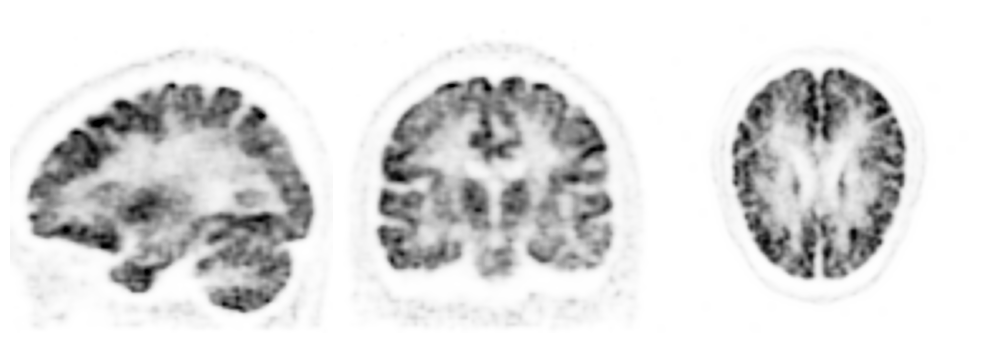

In [11]:
vmax = 0.45
cmap='Greys'
fig, ax = plt.subplots(1,3,figsize=(10,4), gridspec_kw={'wspace': 0.0})
plt.subplot(131)
plt.imshow(recon_primaryonly[50,16:-16].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(132)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(133)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

Note that this is not possible in clinical practice, since we don't know which events are scatters/randoms. The reconstruction above is going to be used as an "ideal" comparison for our reconstruction of all events.

## Reconstruction Correcting For Randoms + Scatters

When time-of-flight information is used, estimation of randoms and scatters slightly changes. Lets first set up the system matrix for reconstruction

In [12]:
detector_ids, _, _ = read_gate('prompts', tof_meta=tof_meta)

Create the sinogram, binned one subset at a time as before:

In [13]:
sinogram = io.PET.listmode_to_sinogram(detector_ids, info, tof_meta=tof_meta)
del detector_ids # the sinogram keeps its own compact copy of the events (0.3 GB instead of 1.2 GB)

### Randoms

In addition to the first two steps of the non-TOF procedure (obtaining a random sinogram and smoothing), we now also need to account for the fact that the number of randoms in each TOF bin is proportional to the length of the TOF bin divided by the total coincidence timing width. We can do this using the `randoms_sinogram_to_sinogramTOF` function. We need to provide the `tof_meta`

In [14]:
detector_ids_delays, _, _ = read_gate('delayeds')

Apply all techniques to get randoms sinogram estimate. The randoms sinogram does not have a TOF dimension since it this same for all TOF bins (if we gave it a TOF dimension and repeated it, then it would use up extra memory)

In [15]:
# Load random events accross all TOF bins
sinogram_randoms_estimate = io.PET.listmode_to_sinogram(detector_ids_delays, info)
sinogram_randoms_estimate = io.PET.smooth_randoms_sinogram(sinogram_randoms_estimate, info, fwhm_r=20, fwhm_theta=7, fwhm_z=40)
sinogram_randoms_estimate = io.PET.randoms_sinogram_to_sinogramTOF(sinogram_randoms_estimate, tof_meta, coincidence_timing_width = 4300) # coinicidence timing window for this GATE simulation was set to 4300ps

### Scatters

Like before (non-TOF sinogram tutorial), lets first get an initial reconstruction without scatter.

In [16]:
# The same attenuation map and normalization sinogram as above
proj_meta = PETSinogramPolygonProjMeta(info, tof_meta)
psf_transform = GaussianFilter(3.)
system_matrix = PETSinogramSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       sinogram_sensitivity = normalization_sinogram,
       N_splits=10,
       attenuation_map=atten_map,
       device=pytomography.device # the projections of each subset stay on the GPU
)
additive_term = sinogram_randoms_estimate.unsqueeze(-1) / system_matrix._compute_sensitivity_sinogram().cpu()
likelihood = PoissonLogLikelihood(
        system_matrix,
        sinogram,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
recon_without_scatter_estimation = recon_algorithm(n_iters, n_subsets)
# The likelihood keeps its last expected counts (one subset, 1.2 GB) and the additive term; the scatter estimate below
# needs only the system matrix
del likelihood, recon_algorithm, additive_term
gc.collect()

2143

There are two additional parameters we need to provide to the function for TOF:

1. `tof_meta`: Provides all the required TOF metadata
2. `num_dense_tof_bins`: The emission integrals in Watson [CITE] are split into multiple regions: this specifies the number of regions. This is independent and seperate from any of the information in `tof_meta`.

With the memory budget set above, the estimate is computed one subset of angles at a time when it is used, like the data (the whole estimate would take another 34.6 GB).

**Note: this takes ~10 minutes to run**

In [17]:
# its peak RAM and GPU memory, before it runs
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, proj_data=sinogram,
                              sinogram_random=sinogram_randoms_estimate, tof_meta=tof_meta,
                              sinogram_interring_stepsize=6, sinogram_intraring_stepsize=6, num_dense_tof_bins=25))
sinogram_scatter_estimate = sss.get_sss_scatter_estimate(
    object_meta = object_meta,
    proj_meta = proj_meta,
    pet_image = recon_without_scatter_estimation,
    attenuation_image = atten_map,
    system_matrix = system_matrix,
    proj_data = sinogram,
    image_stepsize = 6,
    attenuation_cutoff = 0.004,
    sinogram_interring_stepsize = 6,
    sinogram_intraring_stepsize = 6,
    sinogram_random = sinogram_randoms_estimate,
    tof_meta = tof_meta,
    num_dense_tof_bins = 25
    )

Single scatter simulation (TOF, lazy, N_splits 1)
Peak ~ 19.3 GB RAM, 6.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 3.5 GB RAM, 1.7 GB GPU (PET image and attenuation map 0.01 GPU, data 0.6 RAM, randoms 1.6 RAM, system matrix's sensitivity sinogram 1.6 GPU, interpolated estimate (lazy: angle and radius of the sampled ring pairs, host) 1.2 RAM)
  projector chunks: 1.2 GB RAM, 2.5 GB GPU (largest step on the host: interpolation over angle and radius 1.2 RAM, sparse estimate (GPU) 0.4 GPU, interpolation over angle and radius (GPU) 0.6 GPU, scaling (136 subsets) (GPU) 1.5 GPU)
  Python, CUDA, allocator: 8.4 GB RAM, 2.1 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.5 GPU, memory the allocators keep (Windows) 5.3 RAM)
(plus whatever else your script keeps)


This TOF sinogram can be compared to the true scatter in each TOF bin. We'll look at summed profiles like we did above.

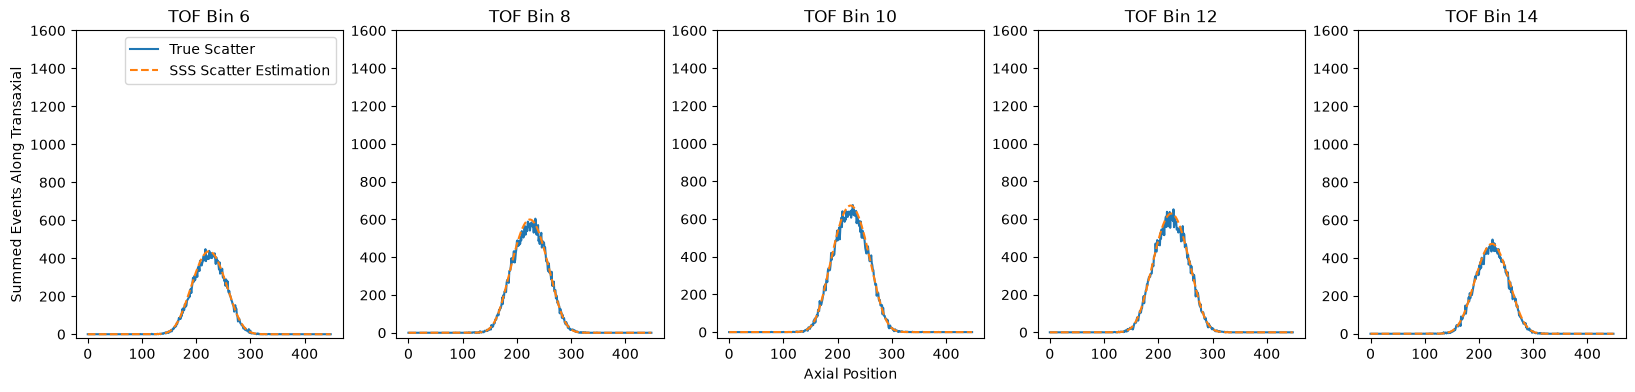

In [18]:
sinogram_scatters_true = io.PET.listmode_to_sinogram(detector_ids_scatters_true, info, tof_meta=tof_meta)
tof_bins = [6,8,10,12,14]
# Both sinograms are summed one group of angles at a time
profiles_true = sinogram_scatters_true[:,:,:64,tof_bins].sum(dim=(0,2))
profiles_estimate = sinogram_scatter_estimate[:,:,:64,tof_bins].sum(dim=(0,2))

fig, ax = plt.subplots(1,5,figsize=(20,4))
# loop TOF bins
for i, idx in enumerate(tof_bins):
    ax[i].plot(profiles_true[:,i], label='True Scatter')
    ax[i].plot(profiles_estimate[:,i], ls='--', label='SSS Scatter Estimation')
    ax[i].set_title(f'TOF Bin {idx}')
    ax[i].set_ylim(top=1600)
ax[0].legend()
ax[2].set_xlabel('Axial Position')
ax[0].set_ylabel('Summed Events Along Transaxial')
plt.show()
del sinogram_scatters_true, detector_ids_scatters_true # only needed for this plot

From the estimated scatter sinogram we can then reconstruct by constructing an additive term like before (non-TOF sinogram tutorial). Since the scatter estimate is computed one subset at a time, so is the additive term.

In [19]:
additive_term = (sinogram_randoms_estimate.unsqueeze(-1) + sinogram_scatter_estimate) / system_matrix._compute_sensitivity_sinogram().cpu()
likelihood = PoissonLogLikelihood(
        system_matrix,
        sinogram,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=n_subsets))
recon_sinogram_TOF = recon_algorithm(n_iters, n_subsets)

OSEM (PETSinogramSystemMatrix): 28 subsets, memory budget 25 GB
Peak ~ 23.6 GB RAM, 8.7 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 5.2 GB RAM, 1.8 GB GPU (sensitivity sinogram 1.6 GPU, normalisation images (28) 0.2 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.6 RAM, additive term 4.5 RAM)
  one subset at a time: 0.00 GB RAM, 3.7 GB GPU (data, expected counts, ratio and temporaries (one subset) 3.7 GPU)
  projector chunks: 0.00 GB RAM, 0.4 GB GPU (projector chunk 0.4 GPU)
  Python, CUDA, allocator: 9.7 GB RAM, 2.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 2.1 GPU, memory the allocators keep (Windows) 6.7 RAM)
To use less: 56 subsets ~ 19.9 GB RAM, 6.2 GB GPU, N_splits 20 ~ 23.2 GB RAM, 8.5 GB GPU
(plus whatever else your script keeps)


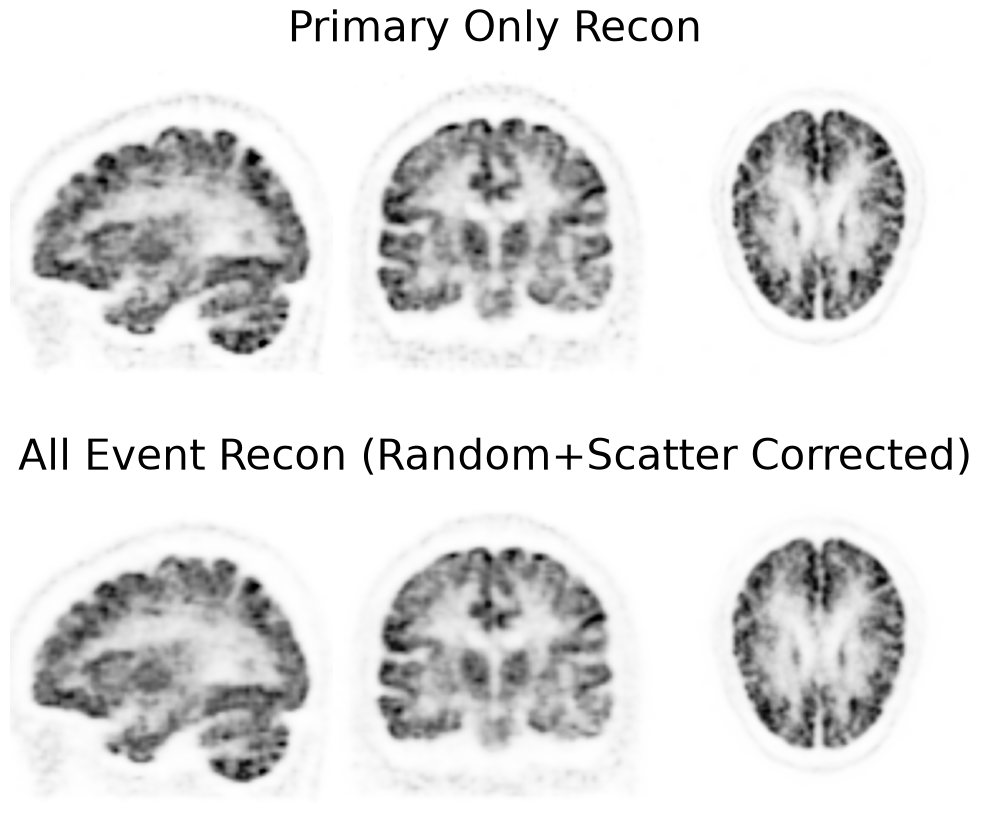

In [20]:
vmax = 0.45
cmap = 'Greys'
fig, ax = plt.subplots(2,3,figsize=(10,9), gridspec_kw={'wspace': 0.0})
plt.subplot(231)
plt.imshow(recon_primaryonly[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Primary Only Recon', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(recon_sinogram_TOF[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(recon_sinogram_TOF[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.title('All Event Recon (Random+Scatter Corrected)', fontsize=30)
plt.subplot(236)
plt.imshow(recon_sinogram_TOF[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so it lines up with that NIfTI file in software that reads both, such as 3D Slicer.

In [21]:
saved = io.save_dicom(recon_sinogram_TOF, OUTPUT / 't_PETGATE_scat_sinoTOF' / 'osem', object_meta,
                      series_description='TOF OSEM, scatter and randoms corrected', overwrite=True)

In [22]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 5.61, "peak_ram_gb": 18.4}
